In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import Binarizer, FunctionTransformer
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

RANDOM_STATE = 0
data_path = './data/digitos_0_1.csv'

### 1. Carga y división de los datos
Cargue los datos y sepárelos en entrenamiento y prueba, utilizando un 20% para prueba, random_state=0 y stratify para preservar la proporción de clases. Separe predictores y etiquetas.

In [3]:
df = pd.read_csv(data_path)

X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).to_dict())
print(y_test.value_counts(normalize=True).to_dict())

(4800, 784) (1200, 784)
{0: 0.5, 1: 0.5}
{1: 0.5, 0: 0.5}


### 2. Procesamiento de datos

Binarice las intensidades utilizando el umbral 127:

- intensidad $>127 \rightarrow 1$;
- intensidad $\le 127 \rightarrow 0$.

Convierta luego los datos a arreglos de NumPy.

In [4]:
binarizador = Binarizer(threshold=127)   # > 127 -> 1, <= 127 -> 0

X_train_bin = binarizador.fit_transform(X_train.to_numpy())
X_test_bin = binarizador.transform(X_test.to_numpy())
y_train_np = y_train.to_numpy()
y_test_np = y_test.to_numpy()

print(type(X_train_bin), X_train_bin.shape, np.unique(X_train_bin))

<class 'numpy.ndarray'> (4800, 784) [0. 1.]


### 3. Visualización de datos

Visualice los primeros 15 dígitos binarizados del conjunto de entrenamiento en una grilla de $3\times5$ y muestre la clase correspondiente a cada imagen. Compare con la Figura 1.

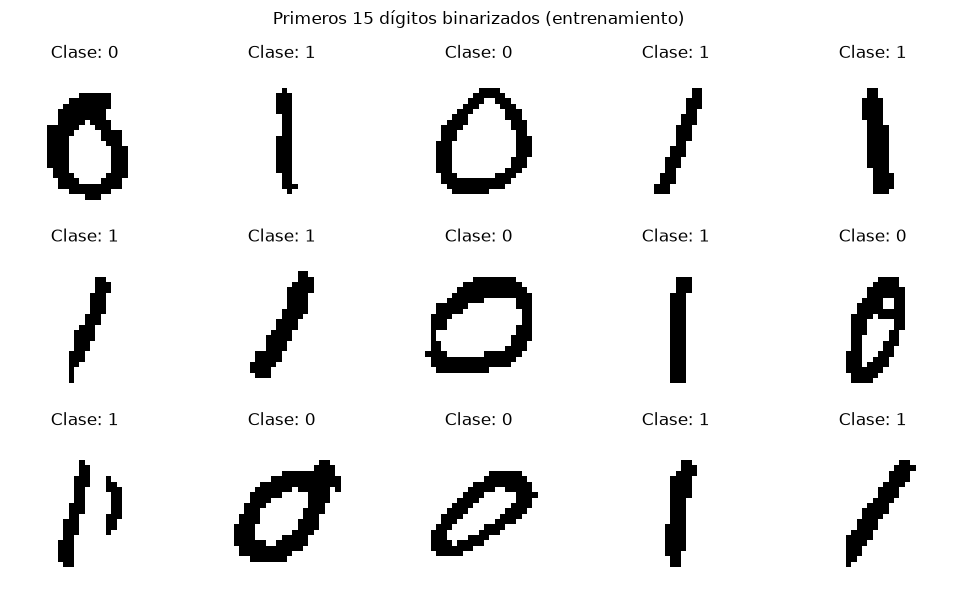

In [5]:
fig, axes = plt.subplots(3, 5, figsize=(10, 6))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train_bin[i].reshape(28, 28), cmap='gray_r')
    ax.set_title(f'Clase: {y_train_np[i]}')
    ax.axis('off')
plt.suptitle('Primeros 15 dígitos binarizados (entrenamiento)')
plt.tight_layout()
plt.show()

Puede notarse que se ha reproducido eficazmente la imagen de referencia, evidenciando un correcto cargado del archivo, una buena binarización y un correcto orden de los datos.

### 4. Cálculo del brillo global

Implemente una función que reciba una imagen binarizada y devuelva la cantidad de píxeles iguales a 0. 

Aplique esta función a cada dígito del conjunto de datos para transformarlo a un conjunto de una única característica.

Aplique la función a entrenamiento y prueba.

Puede utilizar la función [np.apply_along_axis](https://numpy.org/doc/stable/reference/generated/numpy.apply_along_axis.html)

Grafique luego un histograma por clase y compárelo con la Figura 2.

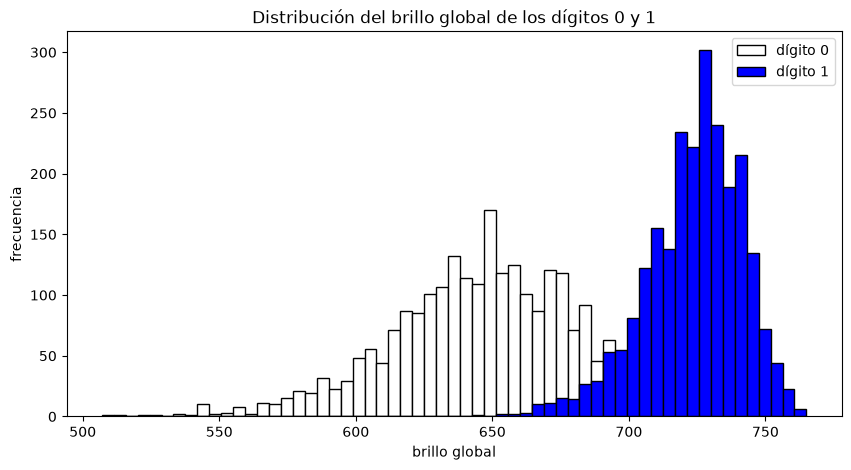

In [6]:
def brillo_global(imagen):
    """Cantidad de píxeles iguales a 0 en una imagen binarizada."""
    return np.sum(imagen == 0)

x_train = np.apply_along_axis(brillo_global, 1, X_train_bin)
x_test = np.apply_along_axis(brillo_global, 1, X_test_bin)

bins = np.linspace(min(x_train.min(), x_test.min()), max(x_train.max(), x_test.max()), 60)
plt.figure(figsize=(10, 5))
plt.hist(x_train[y_train_np == 0], bins=bins, color='white', edgecolor='black', label='dígito 0')
plt.hist(x_train[y_train_np == 1], bins=bins, color='blue', edgecolor='black', label='dígito 1')
plt.xlabel('brillo global'); plt.ylabel('frecuencia')
plt.title('Distribución del brillo global de los dígitos 0 y 1')
plt.legend(); plt.show()

Al igual que en la imagen de referencia, puede observarse que el histograma para el dígito 0 sigue una distribución normal con media cercana a 650 y el dígito 1 sigue una distribución normal con media cercana a 725. Una vez más, puede evidenciarse un correcto seguimiento de lo propuesto.

### 5. Probabilidades a priori y parámetros por clase

Calcule $P(w_0)$ y $P(w_1)$ a partir del conjunto de entrenamiento. 

Calcule además la media y el desvío estándar del brillo global dentro de cada clase.

In [7]:
clases = np.unique(y_train_np)
prior = {c: np.mean(y_train_np == c) for c in clases}
mu = {c: x_train[y_train_np == c].mean() for c in clases}
sigma = {c: x_train[y_train_np == c].std() for c in clases}   # ddof=0, igual que GaussianNB

for c in clases:
    print(f'Clase {c}: P(w_{c}) = {prior[c]:.4f} | media = {mu[c]:.2f} | desvío = {sigma[c]:.2f}')

Clase 0: P(w_0) = 0.5000 | media = 646.44 | desvío = 33.50
Clase 1: P(w_1) = 0.5000 | media = 723.76 | desvío = 17.74


### 6. Modelado de las probabilidades condicionales con distribuciones gaussianas

Para cada clase $w_i$, modele el brillo global como

$$x\mid w_i\sim\mathcal N(\mu_i,\sigma_i^2).$$

Implemente una función para evaluar $p(x\mid w_i)$ utilizando [scipy.stats.norm.pdf](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html). Recuerde que, para una variable continua, la función devuelve una **densidad** y no una probabilidad puntual.

Luego superponga ambas densidades gaussianas sobre los histogramas normalizados (`density=True`) y replique la Figura 3.

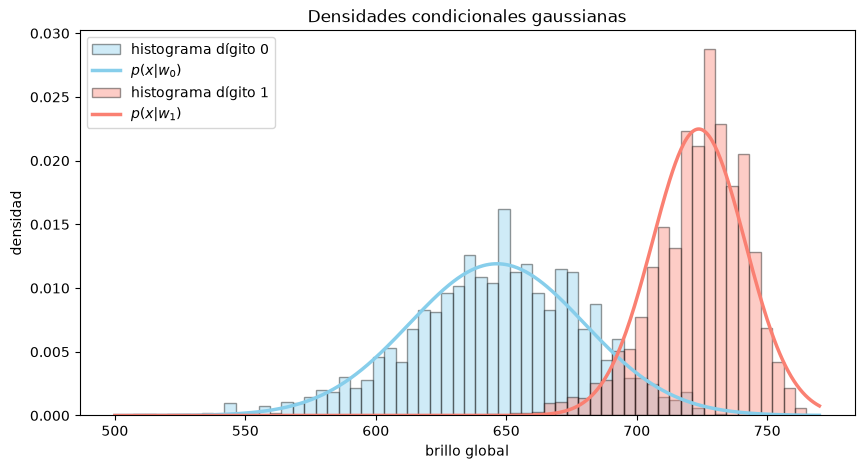

In [8]:
def likelihood(x, clase):
    return stats.norm.pdf(x, loc=mu[clase], scale=sigma[clase])

x_grid = np.linspace(500, 770, 500)
colores = {0: 'skyblue', 1: 'salmon'}

plt.figure(figsize=(10, 5))
for c in clases:
    plt.hist(x_train[y_train_np == c], bins=bins, density=True, alpha=0.4,
             color=colores[c], edgecolor='black', label=f'histograma dígito {c}')
    plt.plot(x_grid, likelihood(x_grid, c), color=colores[c], lw=2.5, label=f'$p(x|w_{c})$')
plt.xlabel('brillo global'); plt.ylabel('densidad')
plt.title('Densidades condicionales gaussianas')
plt.legend(); plt.show()

### 7. Cálculo de la densidad conjunta

Implemente

$$p(x,w_i)=p(x\mid w_i)P(w_i).$$

Grafique ambas densidades conjuntas y replique la Figura 4.

Verifique el valor para $x=724$ y la clase 1 y márquelo en el gráfico.

p(x=724, w_1) = 0.011240


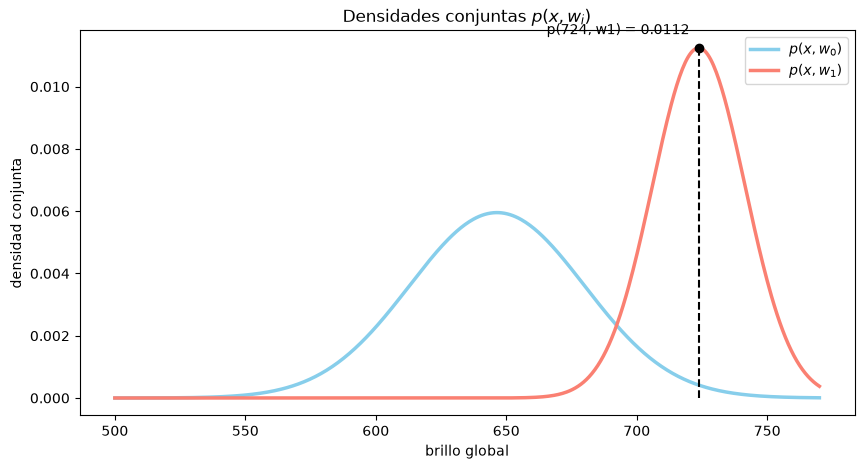

In [9]:
def conjunta(x, clase):
    """p(x, w_clase) = p(x | w_clase) * P(w_clase)."""
    return likelihood(x, clase) * prior[clase]

x0 = 724
val = conjunta(x0, 1)
print(f'p(x={x0}, w_1) = {val:.6f}')

plt.figure(figsize=(10, 5))
for c in clases:
    plt.plot(x_grid, conjunta(x_grid, c), color=colores[c], lw=2.5, label=f'$p(x,w_{c})$')
plt.scatter([x0], [val], color='black', zorder=5)
plt.vlines(x0, 0, val, colors='black', linestyles='--')
plt.annotate(f'p({x0}, w1) = {val:.4f}', (x0, val), textcoords='offset points', xytext=(-110, 10))
plt.xlabel('brillo global'); plt.ylabel('densidad conjunta')
plt.title('Densidades conjuntas $p(x,w_i)$')
plt.legend(); plt.show()

### 8. Cálculo de la densidad marginal

Implemente la suma sobre clases:

$$p(x)=\sum_i p(x\mid w_i)P(w_i).$$

Verifique el valor para $x=724$ y grafique la marginal junto con las densidades conjuntas, replicando la Figura 5.

p(x=724) = 0.011649


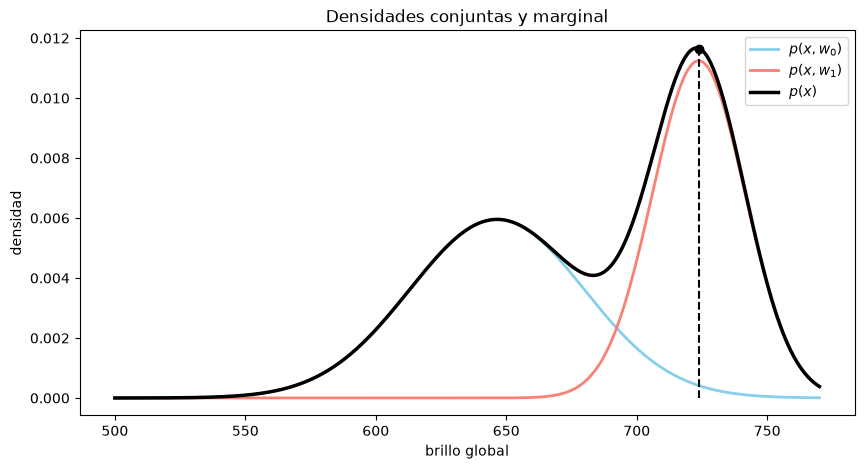

In [10]:
def marginal(x):
    """p(x) = suma sobre clases de p(x | w_i) P(w_i)."""
    return sum(conjunta(x, c) for c in clases)

print(f'p(x={x0}) = {marginal(x0):.6f}')

plt.figure(figsize=(10, 5))
for c in clases:
    plt.plot(x_grid, conjunta(x_grid, c), color=colores[c], lw=2, label=f'$p(x,w_{c})$')
plt.plot(x_grid, marginal(x_grid), color='black', lw=2.5, label='$p(x)$')
plt.scatter([x0], [marginal(x0)], color='black', zorder=5)
plt.vlines(x0, 0, marginal(x0), colors='black', linestyles='--')
plt.xlabel('brillo global'); plt.ylabel('densidad')
plt.title('Densidades conjuntas y marginal')
plt.legend(); plt.show()

### 9. Cálculo de las probabilidades a posteriori

Implemente la regla de Bayes para calcular $P(w_i\mid x)$ para todas las clases.

Verifique los resultados para $x=680$ y $x=724$ y replique la Figura 6.

x = 680: P(w_0|x) = 0.870 | P(w_1|x) = 0.130 | suma = 1.000
x = 724: P(w_0|x) = 0.035 | P(w_1|x) = 0.965 | suma = 1.000


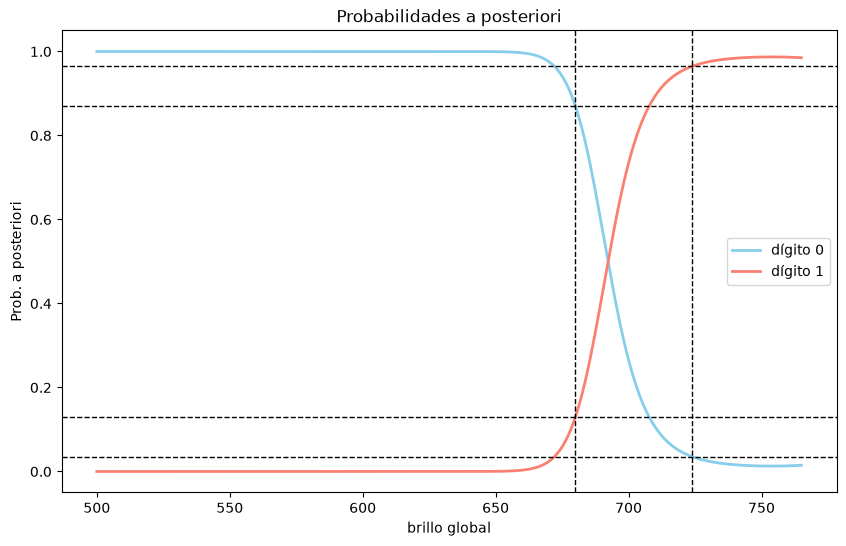

In [11]:
def posteriori(x, clase):
    """Regla de Bayes: P(w_clase | x) = p(x, w_clase) / p(x)."""
    return conjunta(x, clase) / marginal(x)

for xv in (680, 724):
    ps = {c: posteriori(xv, c) for c in clases}
    print(f'x = {xv}: ' + ' | '.join(f'P(w_{c}|x) = {p:.3f}' for c, p in ps.items()),
          f'| suma = {sum(ps.values()):.3f}')

x_plot = np.linspace(500, 765, 500)
plt.figure(figsize=(10, 6))
for c in clases:
    plt.plot(x_plot, posteriori(x_plot, c), color=colores[c], lw=2, label=f'dígito {c}')
for xv in (680, 724):
    plt.axvline(xv, color='black', ls='--', lw=1)
    for c in clases:
        plt.axhline(posteriori(xv, c), color='black', ls='--', lw=1)
plt.xlabel('brillo global'); plt.ylabel('Prob. a posteriori')
plt.title('Probabilidades a posteriori')
plt.legend(); plt.show()

### 10. Regla MAP y clasificación

Para clasificar no es necesario calcular explícitamente $p(x)$, porque el denominador es el mismo para todas las clases. Compruebe que

$$\arg\max_i P(w_i\mid x)=\arg\max_i p(x\mid w_i)P(w_i).$$

Obtenga las predicciones sobre el conjunto de prueba y calcule la exactitud (*accuracy*).

In [13]:
clases_arr = np.array(clases)

post = np.column_stack([posteriori(x_test, c) for c in clases])
pred_post = clases_arr[np.argmax(post, axis=1)]

conj = np.column_stack([conjunta(x_test, c) for c in clases])
pred_map = clases_arr[np.argmax(conj, axis=1)]

print('¿Mismas predicciones?:', np.array_equal(pred_post, pred_map))
acc_manual = accuracy_score(y_test_np, pred_map)
print(f'Accuracy (manual, test): {acc_manual:.4f}')

¿Mismas predicciones?: True
Accuracy (manual, test): 0.9333


Se puede apreciar que ambas predicciones son iguales, confirmando lo supuesto. A la vez, ek accuaracy alcanza un 93,3%

# Comparación con Scikit-Learn

Entrene [GaussianNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html#sklearn.naive_bayes.GaussianNB) utilizando solamente el brillo global. Compare las predicciones y el desempeño con la implementación manual.

Luego inspeccione `class_prior_`, `theta_` y `var_` del objeto entrenado e interprete qué cantidad del desarrollo anterior representa cada atributo.

In [14]:
def brillo_matriz(X):
    return np.apply_along_axis(brillo_global, 1, X).reshape(-1, 1)

pipe_1d = Pipeline([
    ('binarizar', Binarizer(threshold=127)),
    ('brillo', FunctionTransformer(brillo_matriz)),
    ('gnb', GaussianNB()),
])
pipe_1d.fit(X_train.to_numpy(), y_train_np)
pred_sk = pipe_1d.predict(X_test.to_numpy())

print(f'Accuracy sklearn: {accuracy_score(y_test_np, pred_sk):.4f} | manual: {acc_manual:.4f}')
print('Predicciones idénticas:', np.array_equal(pred_sk, pred_map),
      '| discrepancias:', int(np.sum(pred_sk != pred_map)))

gnb = pipe_1d.named_steps['gnb']
print('class_prior_:', gnb.class_prior_)
print('theta_      :', gnb.theta_.ravel())
print('var_        :', gnb.var_.ravel())
print('Varianzas manuales:', [float(sigma[c] ** 2) for c in clases])

Accuracy sklearn: 0.9333 | manual: 0.9333
Predicciones idénticas: True | discrepancias: 0
class_prior_: [0.5 0.5]
theta_      : [646.44333333 723.75583333]
var_        : [1122.38262444  314.86205152]
Varianzas manuales: [1122.3826222222224, 314.8620493055556]


Analizando las métricas obtenidas se puede ver:

-El accuaracy de la implementación manual y la de sklearn son iguales

-Tienen las mismas predicciones y no hay discrepancias

-Los valores de media son iguales para ambas clases

-En el caso de la varianza, se calcula el cuadrado de los desvios estándar y se observa que son iguales (33,5^2 = 1122,38 y 17,74^2 = 314,86)


Se asume entonces que GaussianNB aplica las mismas reglas MAP manuales

# Del clasificador de Bayes al clasificador Naive Bayes
### 1. Cargar y dividir los datos

Vuelva a cargar el CSV, separe predictores y etiquetas y realice una partición 80/20 con `random_state=0` y `stratify=y`.

In [15]:
df = pd.read_csv(data_path)
X = df.drop(columns='target').to_numpy()
y = df['target'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(X_train.shape, X_test.shape, np.bincount(y_train), np.bincount(y_test))

(4800, 784) (1200, 784) [2400 2400] [600 600]


### 2. Binarizar y calcular las dos características

Binarice las imágenes usando el mismo umbral. 

Implemente las funciones necesarias para obtener el brillo global y la cantidad de transiciones entre píxeles vecinos. 

Construya matrices de características de dos columnas para entrenamiento y prueba.

In [16]:
def transiciones(imagen):
    """Cambios 0<->1 entre píxeles vecinos horizontales y verticales."""
    img = imagen.reshape(28, 28)
    horizontales = np.sum(img[:, 1:] != img[:, :-1])
    verticales = np.sum(img[1:, :] != img[:-1, :])
    return horizontales + verticales

def extraer_caracteristicas(X_bin):
    """Matriz (n, 2): [brillo global, transiciones]."""
    return np.column_stack([
        np.apply_along_axis(brillo_global, 1, X_bin),
        np.apply_along_axis(transiciones, 1, X_bin),
    ])

preproc = Pipeline([
    ('binarizar', Binarizer(threshold=127)),
    ('caracteristicas', FunctionTransformer(extraer_caracteristicas)),
])
F_train = preproc.fit_transform(X_train)
F_test = preproc.transform(X_test)

print(F_train.shape, F_test.shape)

(4800, 2) (1200, 2)


### 3. Entrenamiento y evaluación

Entrene `GaussianNB` con las dos características. Obtenga las predicciones, la exactitud, la matriz de confusión y el `classification_report`. Investigue que devuelve `classification_report`

Accuracy: 0.9967

Matriz de confusión (filas = real, columnas = predicho):
[[600   0]
 [  4 596]]

classification_report:
              precision    recall  f1-score   support

    dígito 0       0.99      1.00      1.00       600
    dígito 1       1.00      0.99      1.00       600

    accuracy                           1.00      1200
   macro avg       1.00      1.00      1.00      1200
weighted avg       1.00      1.00      1.00      1200



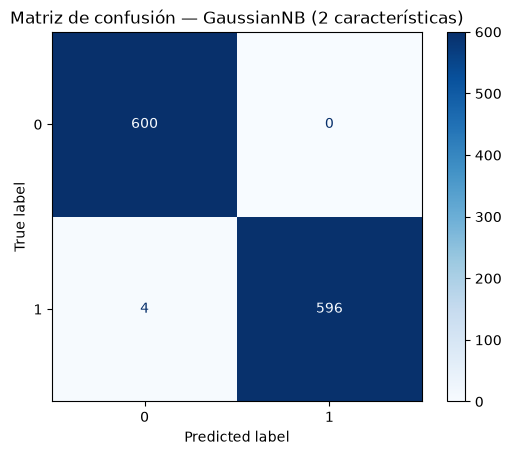

In [17]:
pipe_nb = Pipeline([
    ('binarizar', Binarizer(threshold=127)),
    ('caracteristicas', FunctionTransformer(extraer_caracteristicas)),
    ('gnb', GaussianNB()),
])
pipe_nb.fit(X_train, y_train)
y_pred = pipe_nb.predict(X_test)

print(f'Accuracy: {accuracy_score(y_test, y_pred):.4f}\n')
print('Matriz de confusión (filas = real, columnas = predicho):')
print(confusion_matrix(y_test, y_pred))
print('\nclassification_report:')
print(classification_report(y_test, y_pred, target_names=['dígito 0', 'dígito 1']))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.title('Matriz de confusión — GaussianNB (2 características)')
plt.show()

Se observa que se han clasificado mal cuatro 1s, por lo tanto el recall disminuyó marginalmente. 

Classification report devuelve:
-precision: qué fracción de lo predicho es realmente correcta (verdaderos positivos)
-recall: de lo que realmente es clase k, cuanto se detectó
-f1-score: media armónica de precisión y recall
-support: cantidad de muestras reales de cada clase

### 4. Visualización de la clasificación

Realice un diagrama de dispersión sobre el conjunto de prueba:

- eje X: brillo global;
- eje Y: cantidad de transiciones/bordes;
- color: clase predicha.

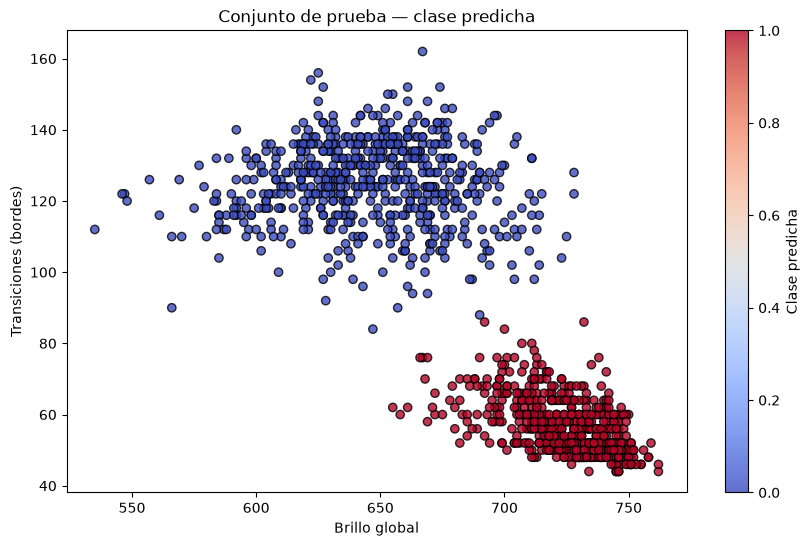

In [18]:
plt.figure(figsize=(10, 6))
sc = plt.scatter(F_test[:, 0], F_test[:, 1], c=y_pred, cmap=plt.cm.coolwarm,
                 edgecolor='black', alpha=0.8)
plt.xlabel('Brillo global'); plt.ylabel('Transiciones (bordes)')
plt.title('Conjunto de prueba — clase predicha')
plt.colorbar(sc, label='Clase predicha')
plt.show()

### 5. Fronteras de decisión

Grafique las regiones de decisión del clasificador sobre el plano de las dos características. Utilice la función provista a continuación y superponga los datos de prueba coloreados según su **clase real**.

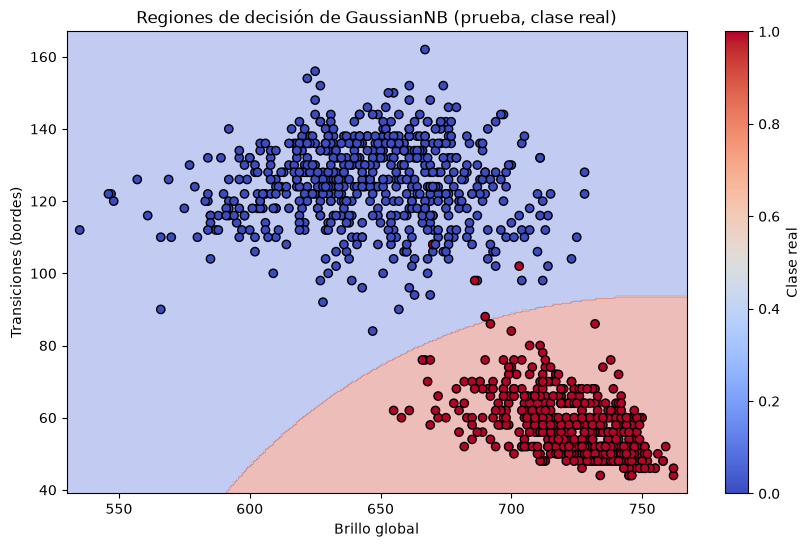

In [20]:
def plot_decision_regions(model, X, y, x_label='Feature 1', y_label='Feature 2', title='Decision regions'):
    """Plot 2D decision regions and true class labels."""
    x_min, x_max = X[:, 0].min() - 5, X[:, 0].max() + 5
    y_min, y_max = X[:, 1].min() - 5, X[:, 1].max() + 5

    x_values = np.linspace(x_min, x_max, 300)
    y_values = np.linspace(y_min, y_max, 300)
    xx, yy = np.meshgrid(x_values, y_values)

    grid = np.column_stack((xx.ravel(), yy.ravel()))
    zz = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(10, 6))
    plt.contourf(xx, yy, zz, alpha=0.35, cmap=plt.cm.coolwarm)
    scatter = plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor='black', cmap=plt.cm.coolwarm)
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)
    plt.colorbar(scatter, label='Clase real')
    plt.show()


plot_decision_regions(pipe_nb.named_steps['gnb'], F_test, y_test,
                      x_label='Brillo global', y_label='Transiciones (bordes)',
                      title='Regiones de decisión de GaussianNB (prueba, clase real)')

### 6. ¿Qué tan razonable es el supuesto *Naive*?

Analice la relación entre las dos características **dentro de cada clase**. Como diagnóstico sencillo, calcule el coeficiente de correlación lineal por clase.

> Importante: correlación nula **no demuestra independencia**. Sin embargo, una correlación claramente distinta de cero sí evidencia dependencia lineal.

En este ejemplo, ¿las dos características parecen cumplir exactamente la independencia condicional?

In [21]:
for c in np.unique(y_train):
    Fc = F_train[y_train == c]
    r = np.corrcoef(Fc[:, 0], Fc[:, 1])[0, 1]
    print(f'Clase {c}: correlación (brillo, transiciones) = {r:+.3f}  (n = {len(Fc)})')

Clase 0: correlación (brillo, transiciones) = +0.015  (n = 2400)
Clase 1: correlación (brillo, transiciones) = -0.540  (n = 2400)
